# 1. Getting started

`lazuli-exo` simulates transmission spectroscopy with the Lazuli IFS. Give it a
showcase planet, an atmosphere scenario and a number of transits, and it returns
the model transmission spectrum binned to the instrument, the 1-sigma error bar
per bin, and a spectral-template S/N.

`import lazuli_exo` needs numpy and nothing else. The atmosphere is a fast
surrogate for POSEIDON (an interpolated opacity grid plus analytic scale-height,
cloud and haze terms) and the noise comes from precomputed slicersim tables.

<div class="alert alert-warning">

**What the numbers mean.** The instrument half (photon and read noise through the
real throughput, readout and line-spread function) is quantitative. The atmosphere
half is a 1D isothermal, equilibrium-chemistry surrogate with statistical noise
only: no P-T profile, no systematics floor. Use the outputs for rankings and
trade studies. Do not quote the template S/N as a detection significance.
[Known approximations](../user_guide/concepts.rst) lists what the model leaves
out.

</div>

In [1]:
import numpy as np
import matplotlib.pyplot as plt

try:
    plt.style.use("gks")
except OSError:
    pass

import lazuli_exo

print("lazuli_exo", lazuli_exo.__file__)

lazuli_exo /Users/gudmundurstefansson/Dropbox/mypylib/notebooks/GIT/lazuli-exo/src/lazuli_exo/__init__.py


## What is available

Fourteen showcase targets, each with the same five scenarios. `list_planets()`
reads the table index; `list_scenarios()` returns the preset names.

In [2]:
planets = lazuli_exo.list_planets()
print(f"{len(planets)} showcase targets\n")
for p in planets:
    print(f"  {p:14s} {lazuli_exo.list_scenarios(p)}")

14 showcase targets

  GJ 1214 b      ['clear', 'cloudy', 'flat', 'hazy', 'high_metallicity']
  GJ 3470 b      ['clear', 'cloudy', 'flat', 'hazy', 'high_metallicity']
  HAT-P-11 b     ['clear', 'cloudy', 'flat', 'hazy', 'high_metallicity']
  HD 189733 b    ['clear', 'cloudy', 'flat', 'hazy', 'high_metallicity']
  HD 209458 b    ['clear', 'cloudy', 'flat', 'hazy', 'high_metallicity']
  K2-18 b        ['clear', 'cloudy', 'flat', 'hazy', 'high_metallicity']
  LHS 1140 b     ['clear', 'cloudy', 'flat', 'hazy', 'high_metallicity']
  TOI-270 d      ['clear', 'cloudy', 'flat', 'hazy', 'high_metallicity']
  TRAPPIST-1 e   ['clear', 'cloudy', 'flat', 'hazy', 'high_metallicity']
  WASP-107 b     ['clear', 'cloudy', 'flat', 'hazy', 'high_metallicity']
  WASP-12 b      ['clear', 'cloudy', 'flat', 'hazy', 'high_metallicity']
  WASP-121 b     ['clear', 'cloudy', 'flat', 'hazy', 'high_metallicity']
  WASP-39 b      ['clear', 'cloudy', 'flat', 'hazy', 'high_metallicity']
  WASP-96 b      ['clear', 'cl

## A single observation

`observe()` takes a planet name, a scenario, the number of transits to co-add
and the resolving power `R` to bin the spectrum to.

In [3]:
obs = lazuli_exo.observe("WASP-39 b", scenario="clear",
                         n_transits=1, R=100)
obs

SimulatedSpectrum(planet='WASP-39 b', scenario='clear', n_transits=1, R=100, wavelength=array([0.40190699, 0.40602614, 0.41002292, 0.41414371, 0.41839785,
       0.42251247, 0.42676633, 0.43115455, 0.4353871 , 0.4397553 ,
       0.44426541, 0.44858246, 0.45303925, 0.45762745, 0.46199533,
       0.46649388, 0.47112947, 0.47590848, 0.48083736, 0.48548913,
       0.49028775, 0.49522273, 0.50031879, 0.50556392, 0.51048025,
       0.51553987, 0.52074953, 0.52611604, 0.53108063, 0.53619294,
       0.54203636, 0.54744845, 0.55239561, 0.55812106, 0.56400375,
       0.56938641, 0.57491445, 0.58059355, 0.58642941, 0.59242805,
       0.59859604, 0.60494014, 0.61063461, 0.61648666, 0.62247512,
       0.62863216, 0.6349353 , 0.64141836, 0.64805763, 0.65389544,
       0.66088367, 0.66804401, 0.67434273, 0.68078809, 0.68738403,
       0.69413446, 0.70104344, 0.70811511, 0.71535367, 0.72276329,
       0.73034802, 0.73811183, 0.74471435, 0.75146009, 0.75972031,
       0.76817334, 0.77536033, 0.78269967

## Anatomy of a `SimulatedSpectrum`

The result is a plain dataclass. You will use `wavelength`, `depth` and
`depth_err` most; `model_wavelength` and `model_depth` keep the native-resolution
model for overplotting.

In [4]:
for name in ["wavelength", "depth", "depth_err",
             "model_wavelength", "model_depth"]:
    arr = getattr(obs, name)
    print(f"{name:18s} shape={str(arr.shape):8s} "
          f"[{arr.min():.6g}, {arr.max():.6g}]")

print()
print(f"{'flat_depth':18s} {obs.flat_depth:.6g}   "
      "# geometric (Rp/Rs)^2 from the registry radii")
print(f"{'R':18s} {obs.R}")
print(f"{'n_transits':18s} {obs.n_transits}")

wavelength         shape=(145,)   [0.401907, 1.68358]
depth              shape=(145,)   [0.0202449, 0.0231421]
depth_err          shape=(145,)   [7.48483e-05, 0.000326857]
model_wavelength   shape=(14430,) [0.399791, 1.69245]
model_depth        shape=(14430,) [0.0199945, 0.0279577]

flat_depth         0.0212285   # geometric (Rp/Rs)^2 from the registry radii
R                  100
n_transits         1


The bins are constant resolving power (snapped to whole detector pixels), so
the bin width grows with wavelength. `depth` is the noiseless model seen through
the instrument and averaged into those bins; `depth_err` is the per-bin 1-sigma
uncertainty.

In [5]:
dlam = np.diff(obs.wavelength)
print(f"{obs.wavelength.size} bins from {obs.wavelength[0]:.3f} "
      f"to {obs.wavelength[-1]:.3f} um")
print(f"bin width: {dlam[0] * 1e3:.2f} nm at the blue end, "
      f"{dlam[-1] * 1e3:.2f} nm at the red end")
print(f"R implied at mid-band: "
      f"{obs.wavelength[len(dlam) // 2] / dlam[len(dlam) // 2]:.0f}")

print(f"\ndepth_err: median {np.median(obs.depth_err) * 1e6:.0f} ppm, "
      f"best {obs.depth_err.min() * 1e6:.0f} ppm, "
      f"worst {obs.depth_err.max() * 1e6:.0f} ppm")

145 bins from 0.402 to 1.684 um
bin width: 4.12 nm at the blue end, 15.73 nm at the red end
R implied at mid-band: 100

depth_err: median 107 ppm, best 75 ppm, worst 327 ppm


## Plotting

`obs.plot()` draws the native-resolution model with one simulated noisy
realization at the binned resolution. It needs the `[plot]` extra (matplotlib).
Every plot method takes an optional `ax` and returns the Axes, so you can pass
your own subplot or overlay several calls; notebook 2 does that.

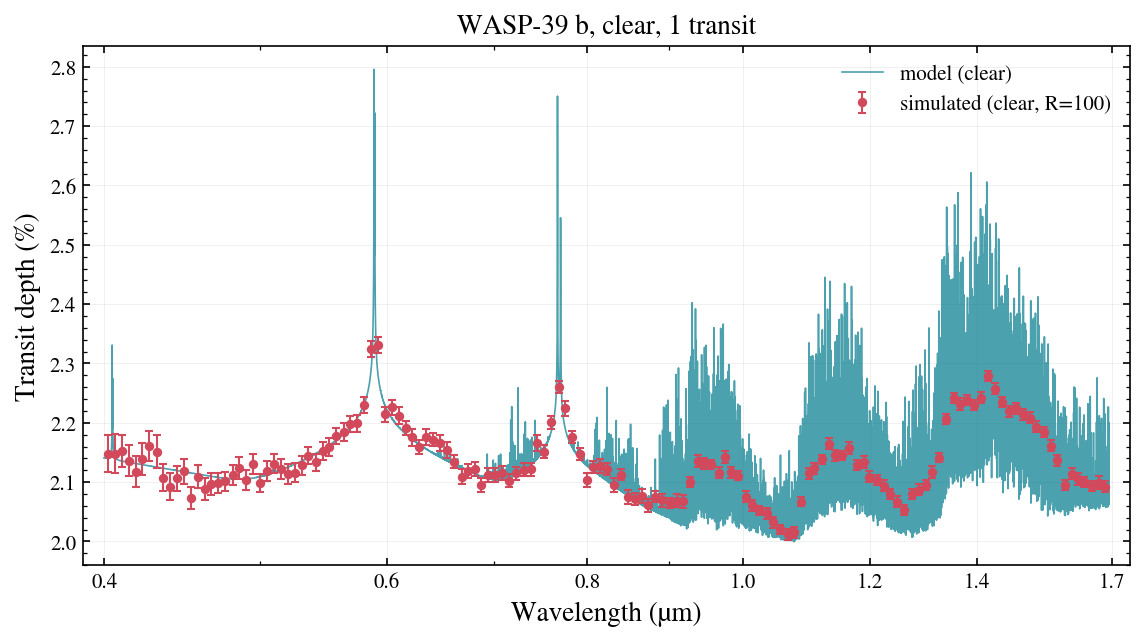

In [6]:
obs.plot(seed=0)
plt.show()

`obs.plot_noise()` shows where the instrument is precise: the per-bin 1-sigma
error against wavelength, with `n_transits` already included.

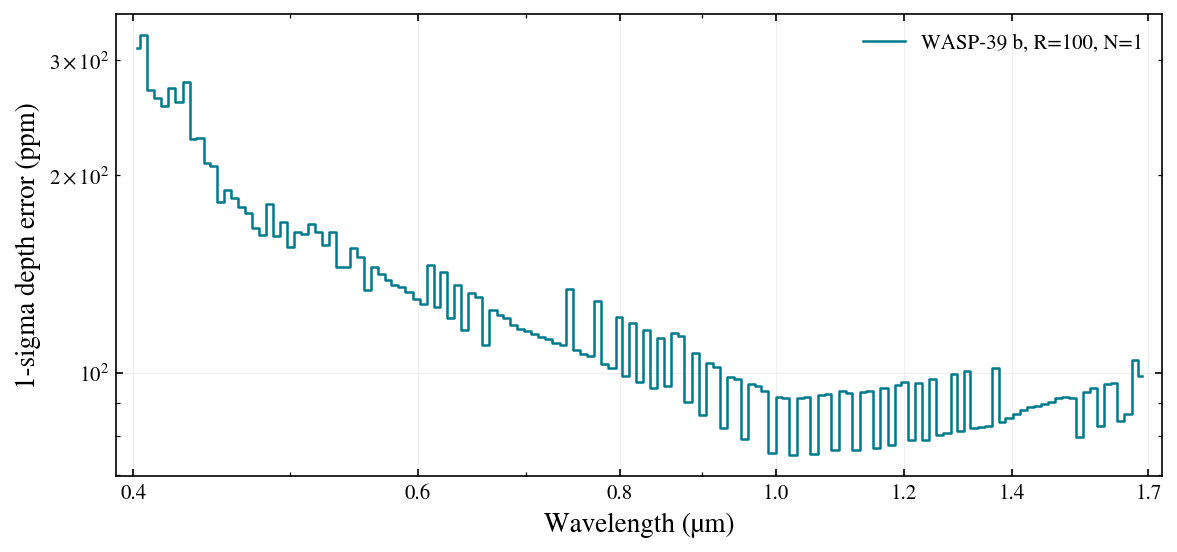

In [7]:
obs.plot_noise()
plt.show()

## Noise realizations

`depth` and `depth_err` are deterministic. The noise is drawn on demand by
`simulate_points(seed)`, and a seed makes a realization reproducible, which is how
the web demo and these notebooks stay stable across runs.

In [8]:
a = obs.simulate_points(seed=0)
b = obs.simulate_points(seed=0)
c = obs.simulate_points(seed=1)

assert np.array_equal(a, b), "same seed must give the same realization"
assert not np.array_equal(a, c), "different seeds must differ"

resid = (a - obs.depth) / obs.depth_err
print(f"same seed reproduces:      {np.array_equal(a, b)}")
print(f"different seed differs:    {not np.array_equal(a, c)}")
print(f"\nresiduals in sigma units: mean {resid.mean():+.3f}, "
      f"std {resid.std():.3f}  (expect ~0 and ~1)")

same seed reproduces:      True
different seed differs:    True

residuals in sigma units: mean +0.080, std 0.954  (expect ~0 and ~1)


## Detection diagnostics

`obs.detect()` returns a matched-template amplitude S/N of the noiseless model
against the best-fit flat line, under a diagonal covariance.

<div class="alert alert-warning">

`template_snr_diagonal` is a comparison statistic, not a calibrated detection
significance: there is no likelihood ratio, no nuisance model, no covariance and
no false-positive calibration. The per-band values are the same statistic
restricted to fixed wavelength masks. They mix every species in the mask with the
haze, cloud and continuum structure, and the masks overlap, so they are not
molecule detections either.

</div>

In [9]:
result = obs.detect()

print(f"template_snr_diagonal: {result['template_snr_diagonal']:.1f}\n")
print("band_snr (band-restricted template norms, NOT detections):")
for mol, snr in sorted(result["band_snr"].items(),
                       key=lambda kv: -kv[1]):
    print(f"  {mol:5s} {snr:7.1f}")

template_snr_diagonal: 68.6

band_snr (band-restricted template norms, NOT detections):
  H2O      46.6
  CO2      26.0
  Na       22.7
  CH4      18.8
  K        15.2


The band masks live in `lazuli_exo.detect.BAND_MASKS`. H2O and CH4 both cover
1.10 to 1.20 µm, which is one reason these are not per-molecule detections.

In [10]:
from lazuli_exo.detect import BAND_MASKS

for mol, spans in BAND_MASKS.items():
    pretty = ", ".join(f"{lo:.3f}-{hi:.3f}" for lo, hi in spans)
    print(f"  {mol:5s} {pretty} um")

  Na    0.575-0.605 um
  K     0.755-0.785 um
  H2O   0.900-1.000, 1.100-1.200, 1.300-1.550 um
  CH4   0.860-0.910, 1.100-1.200, 1.600-1.700 um
  CO2   1.420-1.460, 1.560-1.620 um


## Where the numbers came from

Every observation carries its provenance in `obs.meta`: the parameters the model
was evaluated at (`params`), what the atmosphere model derived from them
(`atmosphere`), the slicersim settings behind the error bars (`noise`) and how
the model was put through the spectrograph (`instrument_response`). This is the
first place to look when a number surprises you.

In [11]:
SHOW = {
    "params": ["T_eq_K", "R_p_RJ", "M_p_MJ", "R_s_RSun", "log_met", "c_to_o",
               "mu", "log_P_cloud_bar", "log_a_haze"],
    "atmosphere": ["g_ms2", "H_m", "H_over_Rp", "mu_used", "mu_source",
                   "T_chem_K", "T_clamped", "feature_amplitude_ppm"],
    "noise": ["instrument", "nmd_used", "t14_s", "t_obs_s", "mag_input", "mag_ab",
              "fully_desaturated", "nsaturated_detpx", "slicersim_version",
              "git_commit"],
    "instrument_response": None,          # all keys
}
for section, keys in SHOW.items():
    d = obs.meta[section]
    print(f"meta[{section!r}]:")
    for k in keys or d:
        v = d[k]
        print(f"  {k:22s} {v:.6g}" if isinstance(v, float) else f"  {k:22s} {v}")
    print()

meta['params']:
  T_eq_K                 1166
  R_p_RJ                 1.33134
  M_p_MJ                 0.281
  R_s_RSun               0.939
  log_met                0
  c_to_o                 0.55
  mu                     None
  log_P_cloud_bar        None
  log_a_haze             None

meta['atmosphere']:
  g_ms2                  3.92911
  H_m                    1.05466e+06
  H_over_Rp              0.0110807
  mu_used                2.32131
  mu_source              chemistry
  T_chem_K               1166
  T_clamped              False
  feature_amplitude_ppm  7963.21

meta['noise']:
  instrument             lazuli_cbe
  nmd_used               [2, 8, 0]
  t14_s                  10091.5
  t_obs_s                48.11
  mag_input              10.663
  mag_ab                 11.5623
  fully_desaturated      True
  nsaturated_detpx       0
  slicersim_version      1.3.4
  git_commit             7d0f71b1f0a36437226d6d26346c74f6baa8dc1f

meta['instrument_response']:
  lsf_sigma_px          

## Summary

- `lazuli_exo.observe(planet, scenario, n_transits, R)` returns a
  `SimulatedSpectrum`.
- `.depth` and `.depth_err` are the noiseless model and its 1-sigma errors;
  `.simulate_points(seed)` draws a reproducible noisy realization.
- `.plot()`, `.plot_noise()` and (notebook 4) `.light_curves().plot()` all take
  `ax=` and return the Axes.
- `.detect()` gives a template S/N: a comparison statistic, not a significance.
- `.meta` records the parameters, the derived atmosphere quantities and the noise
  settings that produced the numbers.

Next: [scenarios](02_scenarios.ipynb), what the five atmosphere scenarios mean
and how they differ.